# Image Generation with Stable Diffusion

**Notebook 2.** An AI model creates a brand-new image from a sentence. This notebook opens the model and shows
what happens inside, step by step, with a picture at every stage.

**Content**

1. What image generation is, and how Stable Diffusion works
2. Text turned into numbers (what the model reads)
3. The starting canvas: pure random noise
4. The denoising loop: the image at every stage, from static to a finished picture
5. How the model learned this (the "reverse movie": picture to noise)
6. The controls: guidance scale, number of steps, seed
7. The metrics: speed, prompt match (CLIP score), variety, and realism (FID)

## What is image generation?

Image generation is the task of **creating a new image that did not exist before**, usually from a text description called a **prompt**.

| Prompt (input) | Output |
|---|---|
| "a cute robot reading a book in a sunny garden, digital art" | A new picture that matches the sentence |

Several families of models can do this. **Stable Diffusion** belongs to the **diffusion** family.

| Family | Main idea |
|---|---|
| **GAN** | Two networks compete: one draws fakes, the other tries to catch them |
| **Diffusion** | A network learns to remove noise from an image, step by step |
| **Autoregressive** | Image pieces are predicted one after another, like words in a sentence |

## How does Stable Diffusion work?

**The fog on a window analogy.** A drawing is hidden behind a thick fog. Wiping the fog a little at a time makes the drawing
appear. Stable Diffusion starts with a canvas that is **100% fog (random noise)** and removes the fog **step by step**.
The text prompt tells the model **which drawing** to reveal.

```
 Prompt: "a cute robot reading a book"
        |
        v
 [ 1. Text encoder (CLIP) ]  ->  numbers that carry the meaning of the sentence
        |
        v                                                    (repeated 20 times)
 Random noise  ->  [ 2. U-Net: predicts the noise ]  ->  [ 3. Scheduler: removes a part of it ]
        ^                                                                  |
        |__________________________________________________________________|
                                      |
                                      v
                          clean "latent" (compressed picture)
                                      |
                                      v
                          [ 4. VAE decoder ]  ->  final image (pixels)
```

| Component | Role (analogy) | What it does |
|---|---|---|
| **Text encoder (CLIP)** | The reader | Converts words into numbers |
| **U-Net** | The artist | Looks at the noisy picture and predicts which part is noise |
| **Scheduler** | The planner | Decides how much noise is removed at each step |
| **VAE decoder** | The printer | Converts the compressed picture into real pixels |

**Why "latent"?** Working directly on a 512 x 512 pixel image means handling 786,432 numbers (512 x 512 x 3 colors).
Stable Diffusion first compresses the image to a **latent** of 64 x 64 x 4 = 16,384 numbers, which is **48 times smaller**.
All the noise removal happens in this small space, which makes generation much faster. The VAE decoder expands the result at the end.

## Step 0: Setup (one time)

Terminal commands, in the folder of this notebook:

```bash
# 1. Create and activate a virtual environment
python -m venv .venv
source .venv/bin/activate            # Windows PowerShell: .venv\Scripts\Activate.ps1

# 2. Install PyTorch
pip install torch                    # NVIDIA GPU or Apple Silicon
# CPU only (smaller download):
# pip install torch --index-url https://download.pytorch.org/whl/cpu

# 3. Install the other tools
pip install ipykernel diffusers transformers accelerate safetensors matplotlib pillow
```

Then in VS Code: **Select Kernel** > **Python Environments** > **.venv**.

**Hardware notes**

| Computer | Expected time for one 512 x 512 image (20 steps) |
|---|---|
| NVIDIA GPU | A few seconds |
| Apple Silicon (MPS) | Around 20 to 60 seconds |
| CPU only | Around 1 to 4 minutes |

The first run downloads the model (roughly 4 to 6 GB), then everything works offline. On a CPU, the optional experiments of
Step 7 are skipped by default because they generate many images.

In [ ]:
%pip install -q torch diffusers transformers accelerate safetensors matplotlib matplotlib-inline pillow ipython ipykernel

## Step 1: Imports and settings

**Libraries**

- `torch`: the engine that runs neural networks
- `diffusers`: the Hugging Face library that contains Stable Diffusion
- `transformers`: contains CLIP, used later to measure how well a picture matches a prompt
- `matplotlib`: draws every figure of this notebook

**Settings** (the control panel of the notebook; a changed value applies after running the cell again)

| Setting | Meaning |
|---|---|
| `PROMPT` | The sentence describing the wanted image |
| `NEGATIVE_PROMPT` | What the image should avoid |
| `SEED` | The number that decides the starting noise. Same seed + same settings = same image |
| `STEPS` | How many times the noise is removed. More steps = more refined, but slower |
| `GUIDANCE` | How strongly the image must follow the prompt (usually 5 to 12) |
| `IMAGE_SIZE` | Width and height in pixels (multiple of 8). 512 is the native size. 384 is faster on a CPU |
| `NUM_SNAPSHOTS` | How many intermediate pictures are captured during the denoising |
| `RUN_EXPERIMENTS` | Runs the comparison experiments of Step 7 (many images, automatic off on CPU) |

In [12]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
from transformers import CLIPModel, CLIPProcessor

# Pick the fastest hardware available
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Running on:", DEVICE)

Running on: cpu


In [13]:
MODEL_ID        = "stable-diffusion-v1-5/stable-diffusion-v1-5"
PROMPT          = "a cute robot reading a book in a sunny garden, digital art"
NEGATIVE_PROMPT = "blurry, low quality, deformed"
SEED            = 42
STEPS           = 20
GUIDANCE        = 7.5
IMAGE_SIZE      = 512
NUM_SNAPSHOTS   = 7
RUN_EXPERIMENTS = DEVICE != "cpu"     # set True to force the experiments on a CPU (slow)

## Step 2: Loading the model

`StableDiffusionPipeline` bundles all components of the diagram into one object.
The **scheduler** is replaced by `DPMSolverMultistepScheduler`, a modern planner that gives good pictures in about 20 steps
(the default one needs around 50).

The number of **parameters** (the adjustable "knobs" learned during training) shows the size of each component.
The U-Net is by far the biggest, since it does the hardest job.

In [14]:
dtype = torch.float16 if DEVICE == "cuda" else torch.float32     # half precision saves memory on GPU

try:
    pipe = StableDiffusionPipeline.from_pretrained(
        MODEL_ID, torch_dtype=dtype, variant="fp16" if DEVICE == "cuda" else None)
except (ValueError, OSError):
    pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=dtype)

pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe = pipe.to(DEVICE)
if DEVICE == "mps":
    pipe.enable_attention_slicing()                                # lowers memory use on Apple chips

parts = {
    "Text encoder (the reader)": pipe.text_encoder,
    "U-Net (the artist)": pipe.unet,
    "VAE (the printer)": pipe.vae,
}
for name, part in parts.items():
    millions = sum(p.numel() for p in part.parameters()) / 1e6
    print(f"{name:<28}{millions:>6.0f} million parameters")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Text encoder (the reader)      123 million parameters
U-Net (the artist)             860 million parameters
VAE (the printer)               84 million parameters


## Step 3: The prompt becomes numbers

A neural network only understands numbers. The text encoder works in two stages:

1. **Tokenizer**: the sentence is cut into pieces (**tokens**), and each token gets an ID number from a dictionary of about 49,000 entries.
2. **Text encoder (CLIP)**: each token becomes a list of **768 numbers** (an **embedding**) that carries its meaning in the context of the sentence.

The sentence is always padded to **77 tokens**. The heatmap shows the first 64 numbers of the embedding for each real token.
Similar meanings produce similar patterns of numbers, and this is what steers the image later.

Token             ID
<|startoftext|>   49406
a                 320
cute              2242
robot             8797
reading           2337
a                 320
book              1116
in                530
a                 320
sunny             5438
garden            2756
,                 267
digital           2794
art               794
<|endoftext|>     49407

Embedding shape: (1, 77, 768) = 1 prompt x 77 tokens x 768 numbers


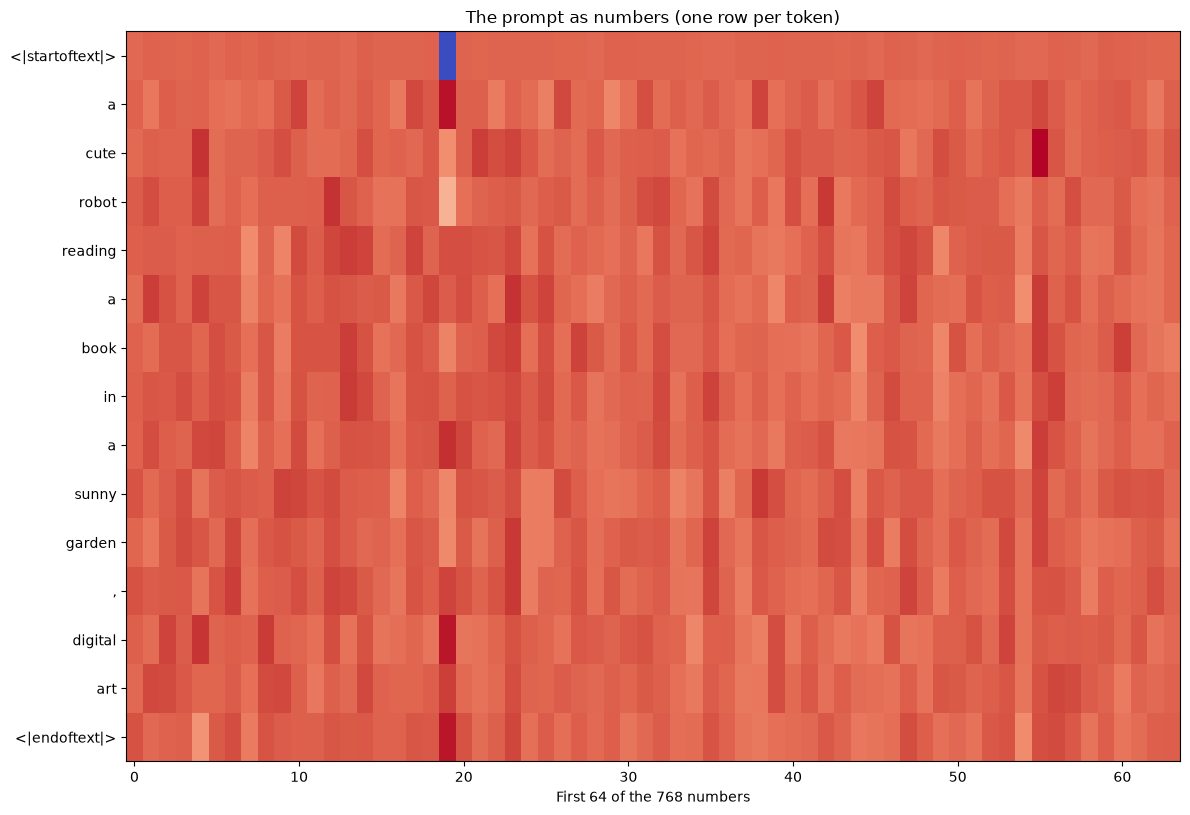

In [16]:
tokenizer = pipe.tokenizer
encoded = tokenizer(PROMPT, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt")
ids = encoded.input_ids[0]
tokens = tokenizer.convert_ids_to_tokens(ids)
n_real = int((ids != tokenizer.pad_token_id).sum())              # start token + the words

print(f"{'Token':<18}ID")
for token, token_id in list(zip(tokens, ids.tolist()))[:n_real + 1]:
    print(f"{token.replace('</w>', ''):<18}{token_id}")

with torch.no_grad():
    embeddings = pipe.text_encoder(ids.unsqueeze(0).to(DEVICE))[0]
print("\nEmbedding shape:", tuple(embeddings.shape), "= 1 prompt x 77 tokens x 768 numbers")

shown = embeddings[0, :n_real + 1, :64].float().cpu().numpy()
labels = [t.replace("</w>", "") for t in tokens[:n_real + 1]]
fig, ax = plt.subplots(figsize=(12, 0.45 * len(labels) + 1.5))
ax.imshow(shown, cmap="coolwarm", aspect="auto")
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_xlabel("First 64 of the 768 numbers")
ax.set_title("The prompt as numbers (one row per token)")
plt.tight_layout()
plt.show()

## Step 4: The starting canvas

Generation starts from **random noise**: a latent of 4 channels, each 64 x 64 numbers drawn from a bell curve
(mean 0, spread 1). It looks like TV static and contains no picture at all.

The **seed** decides these random numbers. The same seed always gives the same noise, which is why a picture can be recreated exactly.
A different seed gives different noise, and therefore a different picture for the same prompt.

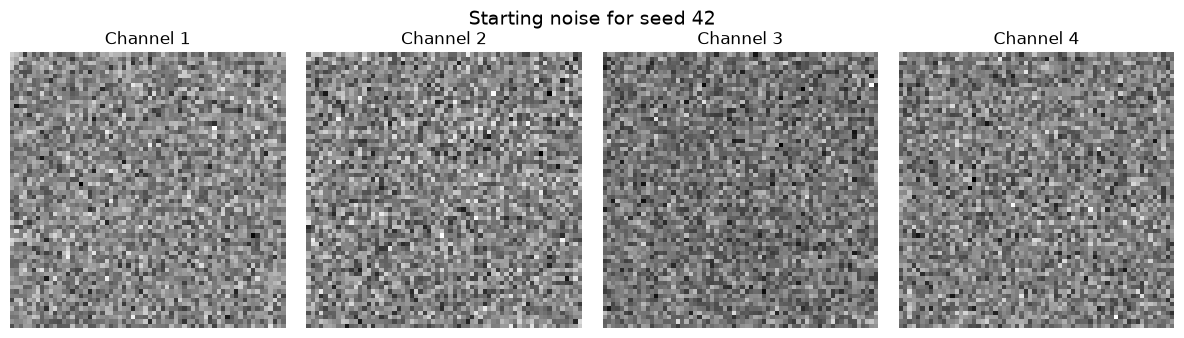

Shape: (1, 4, 64, 64) = 16,384 numbers
Mean = 0.01, spread = 1.00
A 512 x 512 image has 786,432 numbers: the latent is 48 times smaller.


In [17]:
def make_start_latents(seed):
    """Random starting canvas: 4 channels of (IMAGE_SIZE / 8) x (IMAGE_SIZE / 8) numbers."""
    generator = torch.Generator("cpu").manual_seed(seed)
    return torch.randn((1, 4, IMAGE_SIZE // 8, IMAGE_SIZE // 8), generator=generator)


start_latents = make_start_latents(SEED)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for i, ax in enumerate(axes):
    ax.imshow(start_latents[0, i], cmap="gray")
    ax.axis("off")
    ax.set_title(f"Channel {i + 1}")
fig.suptitle(f"Starting noise for seed {SEED}", fontsize=14)
plt.tight_layout()
plt.show()

print("Shape:", tuple(start_latents.shape), f"= {start_latents.numel():,} numbers")
print(f"Mean = {start_latents.mean():.2f}, spread = {start_latents.std():.2f}")
print(f"A {IMAGE_SIZE} x {IMAGE_SIZE} image has {IMAGE_SIZE * IMAGE_SIZE * 3:,} numbers: the latent is "
      f"{IMAGE_SIZE * IMAGE_SIZE * 3 // start_latents.numel()} times smaller.")

## Step 5: The denoising loop

This is the core of Stable Diffusion. At **every step**:

1. The **U-Net** receives the current noisy latent, the current step number, and the prompt numbers.
2. It **predicts the noise** hidden in the latent.
3. The **scheduler** removes a part of that noise. The latent becomes slightly cleaner.

**Classifier-free guidance.** At each step the U-Net actually makes **two predictions**: one that reads the prompt,
and one that ignores it (or reads the negative prompt). The difference between them points **toward the prompt**.
The **guidance scale** decides how far to move in that direction: low = free and creative, high = strict but sometimes over-saturated.

**Seeing inside.** The latent is not a picture, but the VAE decoder can turn it into one at any moment.
The cell below captures the latent at several steps and decodes each one, to show **what the model "sees" along the way**.
The percentage shows the approximate **noise level** that remains after the step.

  0%|          | 0/20 [00:00<?, ?it/s]

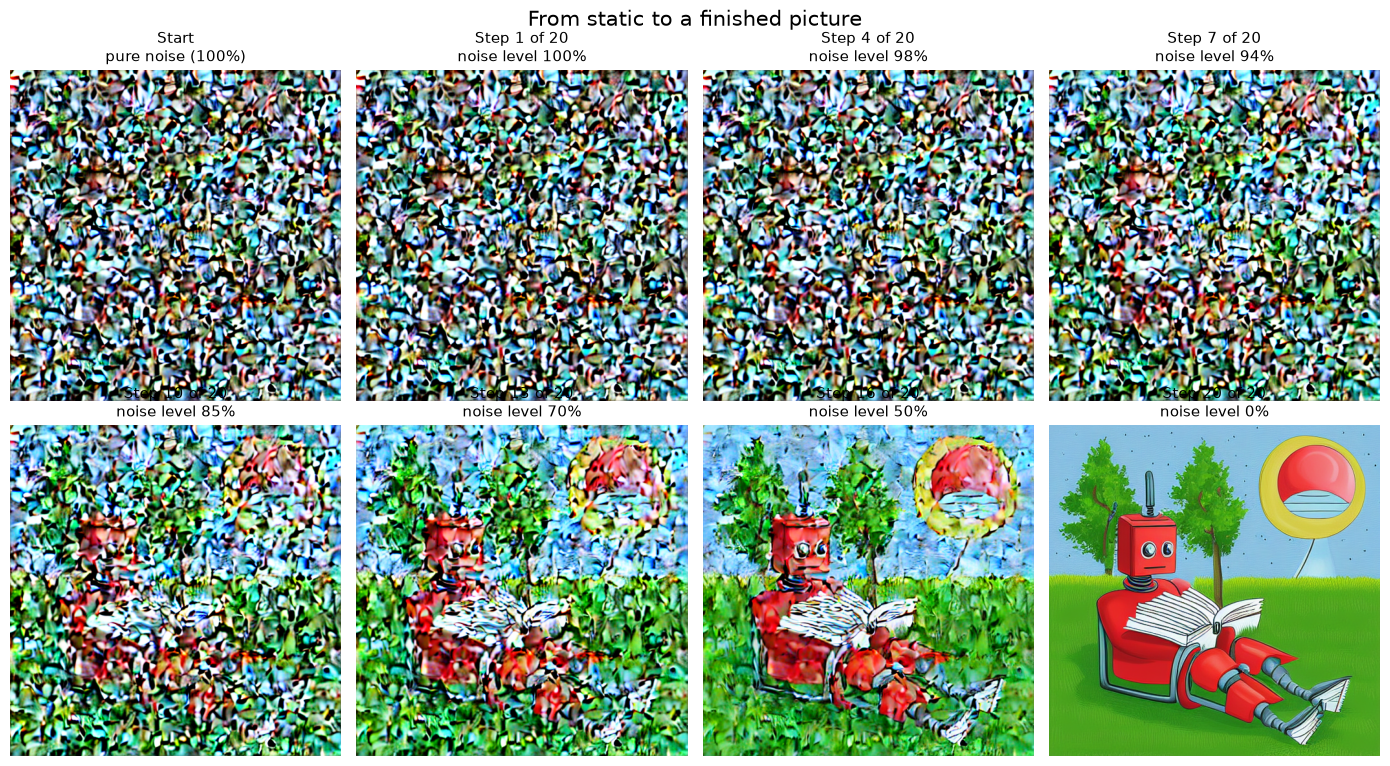

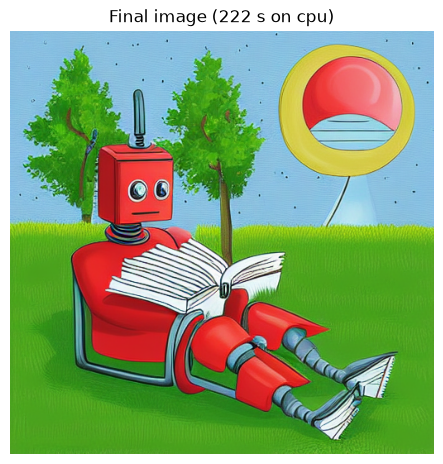

In [18]:
decode_seconds = 0.0
snapshot_steps = sorted(set(np.linspace(0, STEPS - 1, NUM_SNAPSHOTS).astype(int).tolist()))
snapshots = {}


def decode_latents(latents):
    """Latent (compressed picture) -> normal picture, using the VAE decoder."""
    with torch.no_grad():
        image = pipe.vae.decode(latents / pipe.vae.config.scaling_factor).sample
    return pipe.image_processor.postprocess(image, output_type="pil")[0]


def on_step_end(pipeline, step_index, timestep, callback_kwargs):
    """Called after every denoising step: captures the picture at the chosen steps."""
    global decode_seconds
    if step_index in snapshot_steps:
        t0 = time.perf_counter()
        snapshots[step_index] = decode_latents(callback_kwargs["latents"])
        decode_seconds += time.perf_counter() - t0
    return callback_kwargs


start_image = decode_latents(start_latents.to(DEVICE, dtype))      # the picture at step 0: pure noise

t_start = time.perf_counter()
result = pipe(
    prompt=PROMPT,
    negative_prompt=NEGATIVE_PROMPT or None,
    num_inference_steps=STEPS,
    guidance_scale=GUIDANCE,
    latents=start_latents.to(DEVICE, dtype),
    height=IMAGE_SIZE,
    width=IMAGE_SIZE,
    callback_on_step_end=on_step_end,
    callback_on_step_end_tensor_inputs=["latents"],
)
generation_seconds = time.perf_counter() - t_start - decode_seconds   # snapshots excluded from the timing
image = result.images[0]

flags = getattr(result, "nsfw_content_detected", None)
if flags and flags[0]:
    print("The built-in safety checker flagged this image and replaced it with a black picture. Try another prompt or seed.")

# Noise level that remains after each step (from the scheduler's schedule)
alphas = pipe.scheduler.alphas_cumprod
timesteps = pipe.scheduler.timesteps

def noise_left(step_index):
    if step_index + 1 >= len(timesteps):
        return 0.0
    return float((1 - alphas[int(timesteps[step_index + 1])]).sqrt() * 100)


panels = [("Start\npure noise (100%)", start_image)]
for i in snapshot_steps:
    panels.append((f"Step {i + 1} of {STEPS}\nnoise level {noise_left(i):.0f}%", snapshots[i]))

columns = 4
rows = int(np.ceil(len(panels) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(14, 3.9 * rows))
for ax in axes.ravel():
    ax.axis("off")
for ax, (title, picture) in zip(axes.ravel(), panels):
    ax.imshow(picture)
    ax.set_title(title, fontsize=11)
fig.suptitle("From static to a finished picture", fontsize=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5.5, 5.5))
plt.imshow(image)
plt.axis("off")
plt.title(f"Final image ({generation_seconds:.0f} s on {DEVICE})")
plt.show()

## Step 6: How did the model learn this? The reverse movie

The denoising skill was learned by watching the **opposite movie**: a real picture slowly **destroyed by noise**.
During training, millions of images are noised to a random level, and the U-Net must **guess the noise that was added**.
After enough practice, it can do the reverse: given pure noise, it removes the noise step by step and a picture appears.

The formula of the forward movie is simple: at level `t`, the picture is a mix of the original and random noise.

`noisy picture = sqrt(a) x original + sqrt(1 - a) x noise`, where `a` goes from almost 1 (clean) to almost 0 (pure noise).

The cell below applies this formula to the generated image, directly on pixels, to illustrate the idea.
The real model does the same thing on latents. The timestep `t` runs from 0 (clean) to 999 (pure noise).

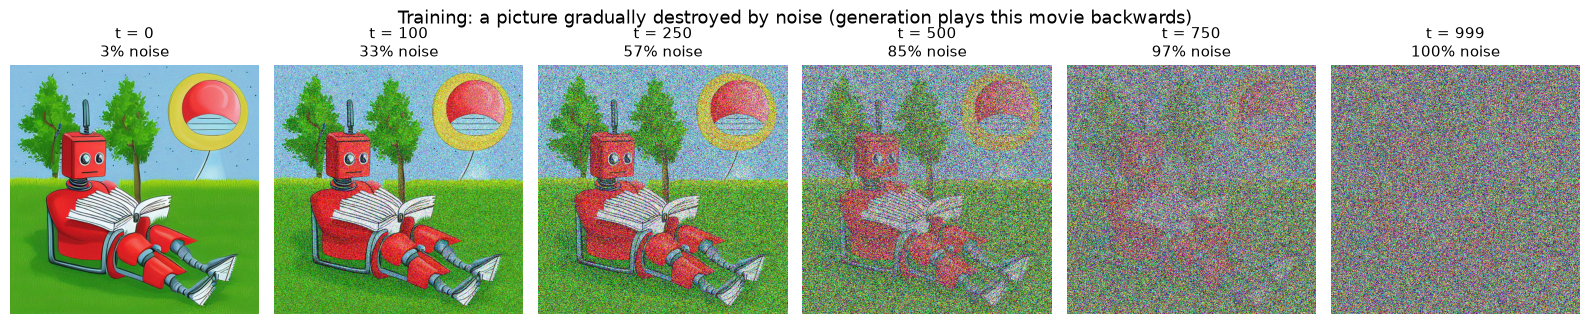

In [19]:
original = np.asarray(image).astype(np.float32) / 127.5 - 1          # pixels scaled to [-1, 1]
noise = np.random.default_rng(SEED).standard_normal(original.shape).astype(np.float32)
alpha_bar = pipe.scheduler.alphas_cumprod.float().cpu().numpy()        # the noise schedule used in training

levels = [0, 100, 250, 500, 750, 999]
fig, axes = plt.subplots(1, len(levels), figsize=(16, 3.4))
for ax, t in zip(axes, levels):
    a = alpha_bar[t]
    noisy = np.sqrt(a) * original + np.sqrt(1 - a) * noise
    ax.imshow(np.clip((noisy + 1) / 2, 0, 1))
    ax.axis("off")
    ax.set_title(f"t = {t}\n{(1 - a) ** 0.5 * 100:.0f}% noise", fontsize=11)
fig.suptitle("Training: a picture gradually destroyed by noise (generation plays this movie backwards)", fontsize=13)
plt.tight_layout()
plt.show()

## Step 7: The controls: guidance, steps, and seed

Three controls change the result. Each experiment changes **one control** and keeps everything else identical.

| Control | Question | What is expected |
|---|---|---|
| **Guidance scale** | How strictly must the prompt be followed? | Low: loose and dreamy. High: strict, but harsh colors and artifacts at extreme values |
| **Number of steps** | How many times is the noise removed? | Few: blurry and unfinished. After around 20: little visible gain, but more time |
| **Seed** | Which random starting noise? | Same prompt, different compositions |

Each experiment generates several images, so it is automatically skipped on a CPU (`RUN_EXPERIMENTS`).
Every image is stored with its generation time, for the metrics in the next section.

In [20]:
def generate(prompt, steps=STEPS, guidance=GUIDANCE, seed=SEED, negative=NEGATIVE_PROMPT):
    """Generate one image. Returns the image and the time it took in seconds."""
    t0 = time.perf_counter()
    out = pipe(prompt=prompt, negative_prompt=negative or None, num_inference_steps=steps,
               guidance_scale=guidance, latents=make_start_latents(seed).to(DEVICE, dtype),
               height=IMAGE_SIZE, width=IMAGE_SIZE)
    return out.images[0], time.perf_counter() - t0


def show_row(title, items):
    fig, axes = plt.subplots(1, len(items), figsize=(3.6 * len(items), 4.3))
    for ax, item in zip(axes, items):
        ax.imshow(item["image"])
        ax.axis("off")
        ax.set_title(f"{item['label']}\n{item['seconds']:.0f} s", fontsize=11)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


GUIDANCE_VALUES = [1, 4, 7.5, 15]
STEP_VALUES     = [3, 6, 12, 25]
SEED_VALUES     = [SEED, 7, 123, 2024]

experiments = {}

if RUN_EXPERIMENTS:
    experiments["guidance"] = []
    for g in GUIDANCE_VALUES:
        picture, seconds = generate(PROMPT, guidance=g)
        experiments["guidance"].append({"label": f"guidance = {g}", "value": g, "image": picture, "seconds": seconds})
    show_row("Same seed, different guidance scale", experiments["guidance"])

    experiments["steps"] = []
    for s in STEP_VALUES:
        picture, seconds = generate(PROMPT, steps=s)
        experiments["steps"].append({"label": f"{s} steps", "value": s, "image": picture, "seconds": seconds})
    show_row("Same seed, different number of steps", experiments["steps"])

    experiments["seeds"] = []
    for sd in SEED_VALUES:
        picture, seconds = generate(PROMPT, seed=sd)
        experiments["seeds"].append({"label": f"seed = {sd}", "value": sd, "image": picture, "seconds": seconds})
    show_row("Same prompt, different seed", experiments["seeds"])
else:
    print("Experiments skipped (CPU detected). Set RUN_EXPERIMENTS = True in Step 1 to run them.")

Experiments skipped (CPU detected). Set RUN_EXPERIMENTS = True in Step 1 to run them.


## Step 8: Metrics: how good is a generated image?

**The difficulty.** For a prompt, there is **no single correct image**. Classification and detection compare an answer
with an answer sheet, but a prompt has millions of valid pictures. Evaluation therefore asks several different questions.

| Question | Metric | Plain meaning | Better when | Live-friendly? |
|---|---|---|---|---|
| How fast? | **Time per image** | Seconds needed, and seconds per step | Lower | Yes |
| Does it match the prompt? | **CLIP score** | A second AI reads the prompt, looks at the picture, and rates the match from 0 to 100 | Higher | Yes |
| Are the pictures varied? | **Diversity** | How different the pictures are across seeds (0 = all the same) | Higher | Yes (needs a few images) |
| Does it look real? | **FID** | Compares a whole pile of real photos with a whole pile of generated ones | **Lower** | **No** (needs thousands of images) |
| Do people like it? | **Human vote** | Raising hands in the audience | Higher | Yes |

**CLIP score in detail.** CLIP is a model trained on hundreds of millions of image and caption pairs. It turns an image and a sentence
into numbers and measures how close they are. A close match gives a high score.
The number has **no absolute meaning**: it is only useful to **compare** images made for the same prompt, or to compare
a prompt against unrelated prompts. A useful reference is the **unrelated prompt test**: the same picture is scored against sentences
that describe something else, and the correct prompt should clearly win.

**FID in detail** (Frechet Inception Distance). 10,000 or more real photos and 10,000 or more generated images are passed through an
image-recognition network. FID measures how different the two **piles** look as a whole (not picture by picture).
`0` would mean the piles are indistinguishable. FID is the standard number in research papers, but it needs a large dataset and a long computation,
so it is **explained here but not computed live**.

**Limits.** CLIP is a model with its own biases, FID depends on the dataset used, and none of them measures beauty.
Human opinion remains the final judge.

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

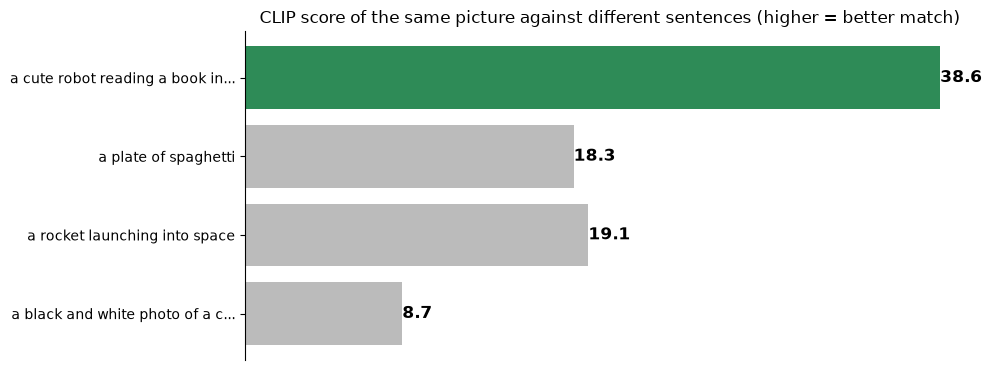

----- Report card of the main image -----
Speed        : 222.1 s in total, 11.11 s per step (cpu)
Prompt match : CLIP score 38.6 (unrelated prompts: 15.4 on average)
Variety      : needs the experiments of Step 7 (several seeds)


In [21]:
# CLIP (a different, smaller model than the one inside Stable Diffusion) acts as the judge. It runs on the CPU.
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


@torch.no_grad()
def clip_look(images, text):
    """Returns the CLIP score (0-100) of each image for the text, and the image vectors."""
    inputs = clip_processor(text=[text], images=images, return_tensors="pt", padding=True)
    out = clip_model(**inputs)
    image_vectors = torch.nn.functional.normalize(out.image_embeds, dim=-1)
    text_vector = torch.nn.functional.normalize(out.text_embeds, dim=-1)
    scores = (100 * image_vectors @ text_vector.T).squeeze(-1).clamp(min=0)
    return scores.reshape(-1).tolist(), image_vectors


# ---- 1. The unrelated prompt test on the main image
UNRELATED_PROMPTS = ["a plate of spaghetti", "a rocket launching into space", "a black and white photo of a city street"]
texts = [PROMPT] + UNRELATED_PROMPTS
scores = [clip_look([image], text)[0][0] for text in texts]

short = [(t[:30] + "...") if len(t) > 30 else t for t in texts]
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(short[::-1], scores[::-1], color=["#BBBBBB"] * len(UNRELATED_PROMPTS) + ["#2E8B57"])
ax.bar_label(bars, fmt="%.1f", fontsize=12, fontweight="bold")
ax.set_title("CLIP score of the same picture against different sentences (higher = better match)")
ax.set_xticks([])
ax.spines[["top", "right", "bottom"]].set_visible(False)
plt.tight_layout()
plt.show()

main_score = scores[0]
print("----- Report card of the main image -----")
print(f"Speed        : {generation_seconds:.1f} s in total, {generation_seconds / STEPS:.2f} s per step ({DEVICE})")
print(f"Prompt match : CLIP score {main_score:.1f} (unrelated prompts: {np.mean(scores[1:]):.1f} on average)")

# ---- 2. The effect of each control on the metrics (only if the experiments were run)
if experiments:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

    g = experiments["guidance"]
    axes[0, 0].plot([e["value"] for e in g], [clip_look([e["image"]], PROMPT)[0][0] for e in g], marker="o", color="#4C78A8")
    axes[0, 0].set_title("Prompt match vs guidance scale")
    axes[0, 0].set_xlabel("Guidance scale")
    axes[0, 0].set_ylabel("CLIP score")

    s = experiments["steps"]
    axes[0, 1].plot([e["value"] for e in s], [clip_look([e["image"]], PROMPT)[0][0] for e in s], marker="o", color="#4C78A8")
    axes[0, 1].set_title("Prompt match vs number of steps")
    axes[0, 1].set_xlabel("Steps")
    axes[0, 1].set_ylabel("CLIP score")

    axes[1, 0].plot([e["value"] for e in s], [e["seconds"] for e in s], marker="o", color="#F58518")
    axes[1, 0].set_title("Time vs number of steps")
    axes[1, 0].set_xlabel("Steps")
    axes[1, 0].set_ylabel("Seconds")

    sd = experiments["seeds"]
    seed_scores, vectors = clip_look([e["image"] for e in sd], PROMPT)
    n = len(sd)
    similarity = vectors @ vectors.T
    diversity = float(1 - (similarity.sum().item() - n) / (n * (n - 1)))   # 1 - average similarity between different pictures
    axes[1, 1].bar([e["label"] for e in sd], seed_scores, color="#2E8B57")
    axes[1, 1].set_title(f"Prompt match for 4 seeds (diversity = {diversity:.2f})")
    axes[1, 1].set_ylabel("CLIP score")
    axes[1, 1].tick_params(axis="x", labelsize=9)

    for ax in axes.ravel():
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

    print(f"Variety      : diversity {diversity:.2f} across {n} seeds (0 = identical pictures, higher = more variety)")
else:
    print("Variety      : needs the experiments of Step 7 (several seeds)")

image.save("generated_image.png")

## Step 9: Recap

| Stage | What happens | Where |
|---|---|---|
| 1. Read | The prompt is cut into tokens, then turned into 77 x 768 numbers | Step 3 |
| 2. Start | A random latent (pure noise) is drawn from the seed | Step 4 |
| 3. Denoise | The U-Net predicts noise, the scheduler removes a part of it, repeated `STEPS` times, guided by the prompt | Step 5 |
| 4. Decode | The VAE turns the clean latent into pixels | Step 5 |
| 5. Learn | Training taught the U-Net by showing it pictures destroyed by noise | Step 6 |
| 6. Control | Guidance, steps, and seed shape the result | Step 7 |
| 7. Evaluate | Speed, CLIP score, diversity, and FID answer different questions | Step 8 |

**Key ideas**

- Diffusion generates an image by **removing noise step by step**, not by drawing it at once.
- The model works on a **small compressed version** (latent) of the image, which makes it fast.
- A **bigger guidance** scale follows the prompt more strictly. More **steps** give diminishing returns.
- No single metric measures quality. **Speed**, **prompt match**, **variety**, and **realism** are measured separately.

## Troubleshooting

| Problem | Solution |
|---|---|
| Out of memory | Lower `IMAGE_SIZE` to 384, close other programs, or use a smaller model such as `segmind/tiny-sd` |
| Very slow on a CPU | Use `STEPS = 15` and `IMAGE_SIZE = 384`, or a GPU environment |
| The image is completely black | The built-in safety checker flagged it. Change the prompt or the seed |
| The first run takes long | The model (several GB) is downloading. It happens once |
| Strange hands, wrong text in images | A known limit of this model generation. Longer prompts and more specific wording help |
| Error about `variant` or `callback_on_step_end` | Update the library: `pip install -U diffusers transformers` |

## Limits and responsible use

- Generated images can reflect **biases** present in the training data.
- Realistic pictures of real people can be used to **mislead** (deepfakes). Generated images should be labelled as AI-made.
- The training data contains work by artists, and the **copyright** of generated images is still debated.